In [1]:
import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm

In [4]:
Sigma1 = 8.0 # g/cm^2 at 1 AU
AU_cm = (1 * u.AU).to(u.cm).value

In [6]:
def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)




def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

In [9]:
# -------------------------------------------------------------
# Region mass split (fractions only; common factors cancel)
# -------------------------------------------------------------
A_INNER_MIN, A_BREAK, A_OUTER_MAX = 0.3, 0.7, 2.0

def mass_split(a_in_min=A_INNER_MIN, a_break=A_BREAK, a_out_max=A_OUTER_MAX):
    # Inner: p(a) ∝ a * Sigma_inner(a) ∝ a(a-0.3)
    F = lambda x: (x**3)/3.0 - 0.15*(x**2)
    Sbreak = sigma_out(a_break)
    M_in_unnorm = (Sbreak / (a_break - a_in_min)) * (F(a_break) - F(a_in_min))
    # Outer: p(a) ∝ a * Sigma_out(a) ∝ a^(-1/2)
    M_out_unnorm = Sigma1 * (2.0 * (np.sqrt(a_out_max) - np.sqrt(a_break)))
    Mtot = M_in_unnorm + M_out_unnorm
    return M_in_unnorm / Mtot, M_out_unnorm / Mtot




# Precompute region selection probability
P_INNER, P_OUTER = mass_split()

In [2]:
def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma


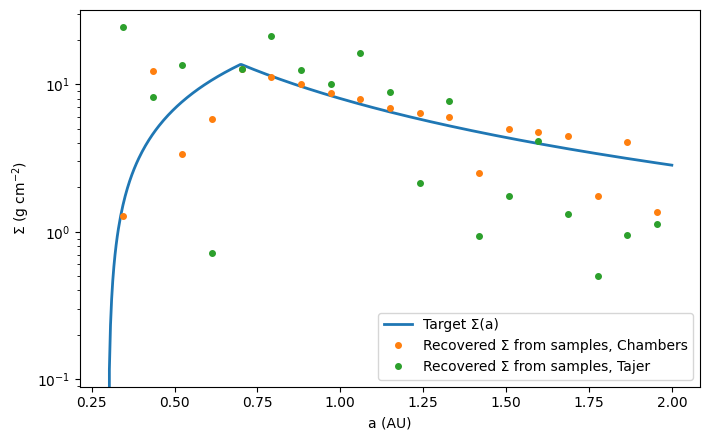

In [15]:
chambers_original_embs = np.loadtxt("semi_major_axes/original_chambers_2013_emb_semis.txt")
chambers_original_pls = np.loadtxt("semi_major_axes/original_chambers_2013_pl_semis.txt")

tajer_embs = np.loadtxt("semi_major_axes/semis_emb_chambers.txt")
tajer_pls = np.loadtxt("semi_major_axes/semis_pl_chambers.txt")


# -------------------------------------------------------------
# Example: Chambers-like setup
# -------------------------------------------------------------
# total mass and counts
#Mtot_sol = 2.604/2 * (u.M_earth.to(u.solMass))  # total solids in solar masses
N = 280
m_pl_sol = 2.8e-8
m_pl_g = m_pl_sol * u.solMass.to(u.g)

# sample semi-major axes from disk
rng = np.random.default_rng(42)
a_samples_emb_tajer_repeat = np.repeat(tajer_embs, 10, axis=0)
a_samples_all_tajer = np.concatenate([a_samples_emb_tajer_repeat, tajer_pls])
a_samples_all_tajer = np.sort(a_samples_all_tajer)


a_samples_emb_chambers_repeat = np.repeat(chambers_original_embs, 10, axis=0)
a_samples_all_chambers = np.concatenate([a_samples_emb_chambers_repeat, chambers_original_pls])
a_samples_all_chambers = np.sort(a_samples_all_chambers)


# Diagnostics plot: recovered surface density vs target laws
centers_cham, sigma_est_cham = compute_surface_density(a_samples_all_chambers, m_pl_g, bins=np.linspace(0.3, 2.0, 20))
centers_tajer, sigma_est_tajer = compute_surface_density(a_samples_all_tajer, m_pl_g, bins=np.linspace(0.3, 2.0, 20))


a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))

plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers_cham, sigma_est_cham, "o", ms=4, label="Recovered Σ from samples, Chambers")
plt.plot(centers_tajer, sigma_est_tajer, "o", ms=4, label="Recovered Σ from samples, Tajer")
plt.yscale("log")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()

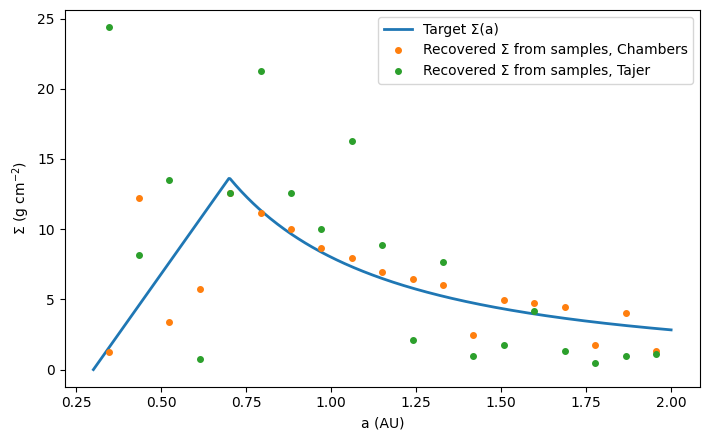

In [16]:
plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers_cham, sigma_est_cham, "o", ms=4, label="Recovered Σ from samples, Chambers")
plt.plot(centers_tajer, sigma_est_tajer, "o", ms=4, label="Recovered Σ from samples, Tajer")
plt.yscale("linear")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()